In [127]:
from pathlib import Path

import numpy as np
import scipy 
import pandas as pd
from scipy.linalg import svdvals
from scipy.io import loadmat
from scipy.optimize import curve_fit
from matplotlib.ticker import MaxNLocator


import matplotlib.pyplot as plt

%matplotlib inline 

In [A temporal record of the past with a spectrum of time constants in the monkey entorhinal cortex](https://www.pnas.org/doi/10.1073/pnas.1917197117#fig02), they found evidence of ramping cell, which they can temporal context cell and also in their subsequent work. Their code and data are posted on [github](https://github.com/tcnlab/TemporalContextCells-ECmonkey). 

In the README.txt, they write

f_average_buffalo.mat: Trial averaged firing rates for cells for all trials,
	novel only, and repeat only.

finalparameters.csv: Contains the parameter values for the 109 temporal context cells. 

From the paper, it says:

`"A total of 349 neurons were recorded from the EC in two macaque monkeys during performance of a visual free-viewing task. Each trial began with a required fixation on a small cross, followed by the presentation of a large, complex image that remained on the screen for 5 s of free viewing."`

Note that in finalparameters.csv, it also contains the unit number for the identified cells

In [128]:
# load cleaned_data_v1.mat
cleaned_data_v1_path = Path("cleaned_data_v1.mat")
cleaned_data_v1 = loadmat(cleaned_data_v1_path)

# load f_average_buffalo.mat
f_average_buffalo_path = Path('f_average_buffalo.mat')
f_average_buffalo = loadmat(f_average_buffalo_path)

# load finaparameters.csv
finalparameters_path = Path('finalparameters.csv')
finalparameters = pd.read_csv(finalparameters_path)

We are going to perform svd analysis on both the 109 temporal context / ramping cells as well as on the whole cell population as a way to make our results more robust.

In [129]:
print(f_average_buffalo.keys())

dict_keys(['__header__', '__version__', '__globals__', 'f_average_single_cell'])


In [130]:
f_rates = f_average_buffalo["f_average_single_cell"]

print("Shape:", f_rates.shape)
print("Data type:", f_rates.dtype)
print("Temporal context cells:", len(finalparameters))
print(finalparameters.head())

Shape: (357, 3, 5500)
Data type: float64
Temporal context cells: 109
   Unit        Mu     Sigma        Tau      Peak       rho
0     9  0.618324  0.001000   0.246152  0.006483  0.672246
1    10  1.023550  0.001000  20.000000 -0.002498  0.999740
2    11  0.096261  0.377574   0.010512  0.313373  0.995049
3    16  0.401944  0.001000  11.759118 -0.001425  0.999515
4    17  0.079217  0.001000   0.362565  0.002150  0.866984


The f_average_buffalo contains 357 cells, but in the paper, they states they only record 349 cells. Therefore, they excludes 8 cells. In the paper, they reported 
there are 8 hippocampal cells recorded. The original excerpt is:

`"One recording session, which other electrode placement metrics suggest was conducted above the EC within the hippocampus, lacked this electrophysiological signature and was excluded from further analysis (eight single neurons were excluded from this session)."`

In the github code, the file loop_process_ML_results.m from Analyses has the following code 

`
%Finds all the parameters for the EC units`

`%Units 238-245 are hippocampal`

`for i = [1:237 246:357]`

so we are going to do the same thing to find the entorhinal neurons.

In [131]:
# Authors' MATLAB unit IDs
# Units 238–245 are hippocampal, not entorhinal
all_unit_ids = np.r_[
    np.arange(1, 238),
    np.arange(246, 358)
]

tcc_unit_ids = finalparameters["Unit"].to_numpy(dtype=int)

# MATLAB condition 3 -> Python index 2
# Convert firing rates from spikes/ms to Hz
R_all = (
    f_rates[all_unit_ids - 1, 2, :] * 1000
)

# Select 109 temporal-context cells
tcc_mask = np.isin(all_unit_ids, tcc_unit_ids)

assert tcc_mask.sum() == 109

R_tcc = R_all[tcc_mask, :]

# Remaining entorhinal cells
R_non_tcc = R_all[~tcc_mask, :]

print("All EC cells:", R_all.shape)
print("Temporal context cells:", R_tcc.shape)
print("Other EC cells:", R_non_tcc.shape)

All EC cells: (349, 5500)
Temporal context cells: (109, 5500)
Other EC cells: (240, 5500)


In [132]:
np.any(R_tcc < 0), np.any(R_all < 0)

(np.False_, np.False_)

In [133]:
def exp_decay(t, A, xi, b):
    return A * np.exp(-xi * t) + b

n_time = R_tcc.shape[1]
dt = 0.001  # seconds, assuming 1 ms samples

# Image onset is 0.5 seconds after the recording window starts
trial_centers = (np.arange(n_time) + 0.5) * dt - 0.5
results = []

for i, y in enumerate(R_all): # i is neuron i, y is firing rate, the data we are going to fit
    try: 
        popt, _ = curve_fit(
            exp_decay,
            trial_centers,
            y,
            p0 = [max(y[0] - y[-1], 0.01), 0.01, max(y[-1], 0)],
            bounds = (0, np.inf),
            maxfev = 10000
        )
        y_pred = exp_decay(trial_centers, *popt)

        ss_res = np.sum((y_pred - y)**2)
        ss_tot = np.sum((y - y.mean())**2)

        r2 = 1 - ss_res / ss_tot

        results.append([i, *popt, r2])
    except RuntimeError:
        results.append([i, np.nan, np.nan, np.nan, np.nan])

df = pd.DataFrame(
    results,
    columns=["neuron", "A", "xi", "baseline", "R2"]
)
df = df.sort_values("R2", ascending=False)
print(df.head(109))

     neuron         A        xi      baseline        R2
249     249  1.434459  0.300822  1.175363e+00  0.728054
258     258  1.610833  0.430959  9.000062e-01  0.638734
9         9  2.687055  0.513855  2.343800e+00  0.582818
10       10  2.318792  0.754682  1.787628e+00  0.541101
40       40  1.897738  0.669952  1.153376e+00  0.532317
..      ...       ...       ...           ...       ...
57       57  0.640219  0.072050  2.005630e-12  0.106245
81       81  0.531843  0.188989  1.239391e+00  0.104568
154     154  0.194910  0.814119  7.442172e-01  0.104337
148     148  1.411701  0.276555  1.370475e+00  0.100655
8         8  9.754750  0.025659  2.233730e-09  0.100575

[109 rows x 5 columns]


In [135]:
R_tcc_mean = R_tcc.mean(axis=1, keepdims=1)
R_tcc_mean_subtracted = R_tcc - R_tcc_mean
np.max(R_tcc_mean), np.where(R_tcc_mean_subtracted < 0)

(np.float64(22.559748181378367),
 (array([  0,   0,   0, ..., 108, 108, 108], shape=(345857,)),
  array([   0,    1,    2, ..., 5497, 5498, 5499], shape=(345857,))))

In [137]:
print(s_all[0], s_all[-1])
print(s_tcc[0], s_tcc[-1])
print(s_tcc_normalized[-1])

5289.913157395177 0.06471545427841036
695.8570867601618 0.5822170767663305
0.0008366905904157312


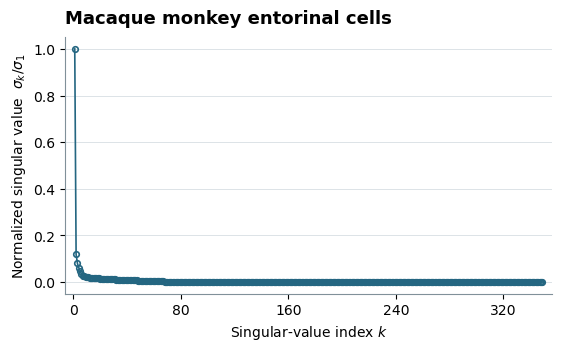

In [139]:
s_all = svdvals(R_all)
s_tcc = svdvals(R_tcc_mean_subtracted)

s_all_normalized = s_all / s_all[0]
s_tcc_normalized = s_tcc / s_tcc[0]

normalized = s_all_normalized

n_show = normalized.shape[0]
k = np.arange(1, n_show + 1)

fig, ax = plt.subplots(figsize=(5.5, 3.4), layout="constrained")

ax.plot(
    k, normalized[:n_show],
    color="#246681",
    linewidth=1.2,
    marker="o",
    markersize=4,
    markerfacecolor="none",
    markeredgecolor="#246681",
    markeredgewidth=1.2,
)

ax.set_title("Macaque monkey entorinal cells", loc="left", fontsize=13,
             fontweight="bold", pad=10)
ax.set_xlabel(r"Singular-value index $k$")
ax.set_ylabel(r"Normalized singular value  $\sigma_k/\sigma_1$")
# ax.set_ylim(-0.05, 1.05)
ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
ax.margins(x=0.02)

ax.set_axisbelow(True)
ax.grid(axis="y", color="#dce3e7", linewidth=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#809099")

fig.savefig(f"bright_svd_{n_show}.pdf", bbox_inches="tight")
plt.show()